# Embedding Space Analysis — RAG Pipeline Quality Evaluation

This notebook performs a systematic analysis of the embedding space produced by the RAG pipeline. The goal is to evaluate:

- **Distribution**: How are chunks spread across the embedding space?
- **Coherence**: Do semantically related chunks cluster together?
- **Coverage**: Are all document sections well-represented?
- **Quality**: Did the chunking strategy produce meaningful semantic units?

This is a diagnostic tool for ML engineers evaluating the quality of a RAG pipeline before deploying it to production.

---
## 1. Environment Setup

Install and import all required libraries. We use:
- `qdrant-client` to retrieve vectors from the vector database
- `umap-learn` for dimensionality reduction
- `hdbscan` for density-based clustering
- `plotly` for interactive visualizations
- `scikit-learn` for KMeans and additional metrics
- `pandas` / `numpy` for data manipulation

In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
import warnings

from qdrant_client import QdrantClient
from qdrant_client.models import Filter

import umap
import hdbscan
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import LabelEncoder
from scipy.spatial.distance import cdist

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

# Matplotlib style
plt.style.use("seaborn-v0_8-whitegrid")
RANDOM_STATE = 42

# Plotly renderer — "vscode" is required for VS Code notebooks
pio.renderers.default = "vscode"

print("All libraries imported successfully.")
print(f"Plotly renderer: {pio.renderers.default}")

All libraries imported successfully.
Plotly renderer: vscode


In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings

from qdrant_client import QdrantClient
from qdrant_client.models import Filter

import umap
import hdbscan
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.preprocessing import LabelEncoder
from scipy.spatial.distance import cdist

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

# Matplotlib style
plt.style.use("seaborn-v0_8-whitegrid")
RANDOM_STATE = 42

print("All libraries imported successfully.")

All libraries imported successfully.


---
## 2. Connecting to Qdrant

We connect to the local Qdrant instance and verify access to the target collection. Before loading vectors, we inspect collection metadata to understand:
- Vector dimensionality
- Total number of points
- Distance metric used during indexing

In [71]:
# ── Configuration ──────────────────────────────────────────────────────────────
QDRANT_URL        = "http://10.0.50.90:6333"
COLLECTION_NAME   = "chunking_alejandro"
BATCH_SIZE        = 100   # points per scroll request
# ───────────────────────────────────────────────────────────────────────────────

client = QdrantClient(url=QDRANT_URL)

# Verify connection and inspect collection
collection_info = client.get_collection(COLLECTION_NAME)
vector_size     = collection_info.config.params.vectors.size
total_points    = collection_info.points_count
distance_metric = collection_info.config.params.vectors.distance

print(f"Collection : {COLLECTION_NAME}")
print(f"Points     : {total_points:,}")
print(f"Vector dim : {vector_size}")
print(f"Distance   : {distance_metric}")

Collection : chunking_alejandro
Points     : 1,343
Vector dim : 768
Distance   : Cosine


---
## 3. Loading Embeddings

We scroll through the entire collection using Qdrant's `scroll` API to retrieve all vectors along with their associated metadata (payload). Qdrant does not support bulk export in a single call, so we paginate using an offset cursor until all points are retrieved.

Metadata fields extracted per point:
- `document` — source document name
- `section` — section or chapter within the document
- `chunk_text` — raw text of the chunk
- `chunk_id` — unique identifier

In [72]:
def scroll_all_points(client: QdrantClient, collection: str, batch_size: int = 100):
    """Retrieve all points (vectors + payloads) from a Qdrant collection."""
    records = []
    offset  = None

    while True:
        results, next_offset = client.scroll(
            collection_name = collection,
            limit           = batch_size,
            offset          = offset,
            with_vectors    = True,
            with_payload    = True,
        )
        records.extend(results)

        if next_offset is None:
            break
        offset = next_offset

        if len(records) % 500 == 0:
            print(f"  Retrieved {len(records):,} points so far…")

    return records


print(f"Fetching all points from '{COLLECTION_NAME}'…")
all_points = scroll_all_points(client, COLLECTION_NAME, BATCH_SIZE)
print(f"Done — {len(all_points):,} points retrieved.")

Fetching all points from 'chunking_alejandro'…
  Retrieved 500 points so far…
  Retrieved 1,000 points so far…
Done — 1,343 points retrieved.


---
## 4. Preparing the Dataset

We convert the raw Qdrant records into a structured `pandas.DataFrame`. The embedding vectors are stored as a separate NumPy matrix (`embeddings_matrix`) for efficient numerical operations downstream.

We also compute basic dataset statistics to understand the composition of the corpus before running any analysis.

In [73]:
def build_dataframe(points):
    """Convert Qdrant scroll results into a DataFrame + embedding matrix."""
    rows       = []
    embeddings = []

    for pt in points:
        payload = pt.payload or {}
        rows.append({
            "qdrant_id"  : pt.id,
            "chunk_id"   : payload.get("chunk_id",   str(pt.id)),
            "document"   : payload.get("document",   "unknown"),
            "section"    : payload.get("section",    "unknown"),
            "chunk_text" : payload.get("chunk_text", ""),
            "token_count": payload.get("token_count", None),
        })
        embeddings.append(pt.vector)

    df  = pd.DataFrame(rows)
    mat = np.array(embeddings, dtype=np.float32)
    return df, mat


df, embeddings_matrix = build_dataframe(all_points)

# Derive a short text preview for hover tooltips
df["text_preview"] = df["chunk_text"].str[:120] + "…"

print(f"DataFrame shape    : {df.shape}")
print(f"Embeddings matrix  : {embeddings_matrix.shape}")
print(f"\nDistinct documents : {df['document'].nunique()}")
print(f"Distinct sections  : {df['section'].nunique()}")
print()
df.head(3)

DataFrame shape    : (1343, 7)
Embeddings matrix  : (1343, 768)

Distinct documents : 3
Distinct sections  : 183



,qdrant_id,chunk_id,document,section,chunk_text,token_count,text_preview
0,00280c76-6b40-5ae8-9d65-84ad95f09b09,134,LIFTOFF_DOE_VPP_2023,Capacity from EVs (including both charging demand,"There are additional considerations for bidirectional EV chargers; for example, the electrical infrastructure suppor...",42,"There are additional considerations for bidirectional EV chargers; for example, the electrical infrastructure suppor..."
1,00408ded-5563-5ade-a050-d30373f7ffa2,253,potential-benefits-high-power-high-capacity-batteries-january-2020,Industry Studies,"112 California ISO, 'Supplemental Sensitivity Analysis: Benefits Analysis of Large Energy Storage,' January 4, 2018....",78,"112 California ISO, 'Supplemental Sensitivity Analysis: Benefits Analysis of Large Energy Storage,' January 4, 2018...."
2,005474a5-e33c-56d5-9bd5-b5380aa6b592,534,LIFTOFF_DOE_VPP_2023,VIII. Overview of VPP Business model cost and revenue drivers,"Admin.\n\neducation,\n\nThe following schematic of VPP costs and revenues is simplified for instructive purposes.\n\...",96,"Admin.\n\neducation,\n\nThe following schematic of VPP costs and revenues is simplified for instructive purposes.\n\..."


In [74]:
# Dataset composition overview
print("=== Chunks per document ===")
print(df["document"].value_counts().to_string())
print("\n=== Chunks per section ===")
print(df["section"].value_counts().to_string())

=== Chunks per document ===
document
LIFTOFF_DOE_VPP_2023                                                  674
potential-benefits-high-power-high-capacity-batteries-january-2020    526
Technology Strategy Assessment - Lithium-ion_0                        143

=== Chunks per section ===
section
References                                                                                                                                                                                                                 96
DOE Activity                                                                                                                                                                                                               52
Deployment Examples                                                                                                                                                                                                        43
Ability to Provide Functional Requireme

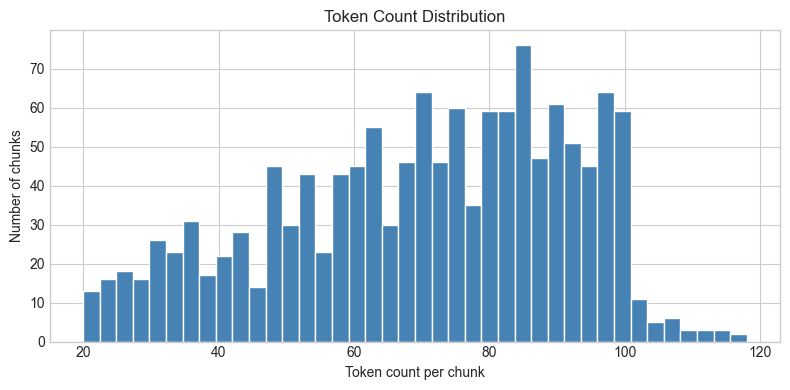

count    1343.000000
mean       69.923306
std        21.729215
min        20.000000
25%        54.000000
50%        72.000000
75%        87.000000
max       118.000000
Name: token_count, dtype: float64


In [75]:
# Token count distribution (if available)
if df["token_count"].notna().any():
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(df["token_count"].dropna(), bins=40, color="steelblue", edgecolor="white")
    ax.set_xlabel("Token count per chunk")
    ax.set_ylabel("Number of chunks")
    ax.set_title("Token Count Distribution")
    plt.tight_layout()
    plt.show()
    print(df["token_count"].describe())
else:
    print("token_count not available in payload — skipping distribution plot.")

---
## 5. UMAP Dimensionality Reduction

High-dimensional embedding vectors cannot be visualized directly. We use **UMAP** (Uniform Manifold Approximation and Projection) to project the embeddings into 2D space while preserving local neighborhood structure.

Key hyperparameters:
- `n_neighbors=15` — balances local vs. global structure; larger values produce more globally-aware layouts
- `min_dist=0.1` — controls how tightly points are packed; lower values emphasize cluster separation
- `metric='cosine'` — appropriate for normalized sentence embeddings where direction, not magnitude, encodes meaning

> **Caveat**: UMAP is a stochastic algorithm. The layout may vary across runs, but relative cluster structure should remain stable.

In [76]:
print("Running UMAP… (this may take a moment for large collections)")

reducer = umap.UMAP(
    n_neighbors  = 15,
    min_dist     = 0.1,
    metric       = "cosine",
    n_components = 2,
    random_state = RANDOM_STATE,
    verbose      = False,
)

umap_2d = reducer.fit_transform(embeddings_matrix)

df["umap_x"] = umap_2d[:, 0]
df["umap_y"] = umap_2d[:, 1]

print(f"UMAP output shape: {umap_2d.shape}")
print(f"X range: [{umap_2d[:, 0].min():.2f}, {umap_2d[:, 0].max():.2f}]")
print(f"Y range: [{umap_2d[:, 1].min():.2f}, {umap_2d[:, 1].max():.2f}]")

Running UMAP… (this may take a moment for large collections)
UMAP output shape: (1343, 2)
X range: [-0.68, 9.69]
Y range: [4.39, 11.05]


---
## 6. Embedding Visualization

We produce several complementary views of the embedding space:

1. **Colored by section** — reveals whether the chunking strategy preserves thematic structure
2. **Colored by document** — shows whether document origin is encoded in the embeddings
3. **Interactive Plotly scatter** — allows hover inspection of individual chunk texts

If chunks from the same section cluster tightly, the embeddings are semantically coherent. If chunks are uniformly distributed, the model may not distinguish topics well — or the chunks themselves may lack semantic distinctiveness.

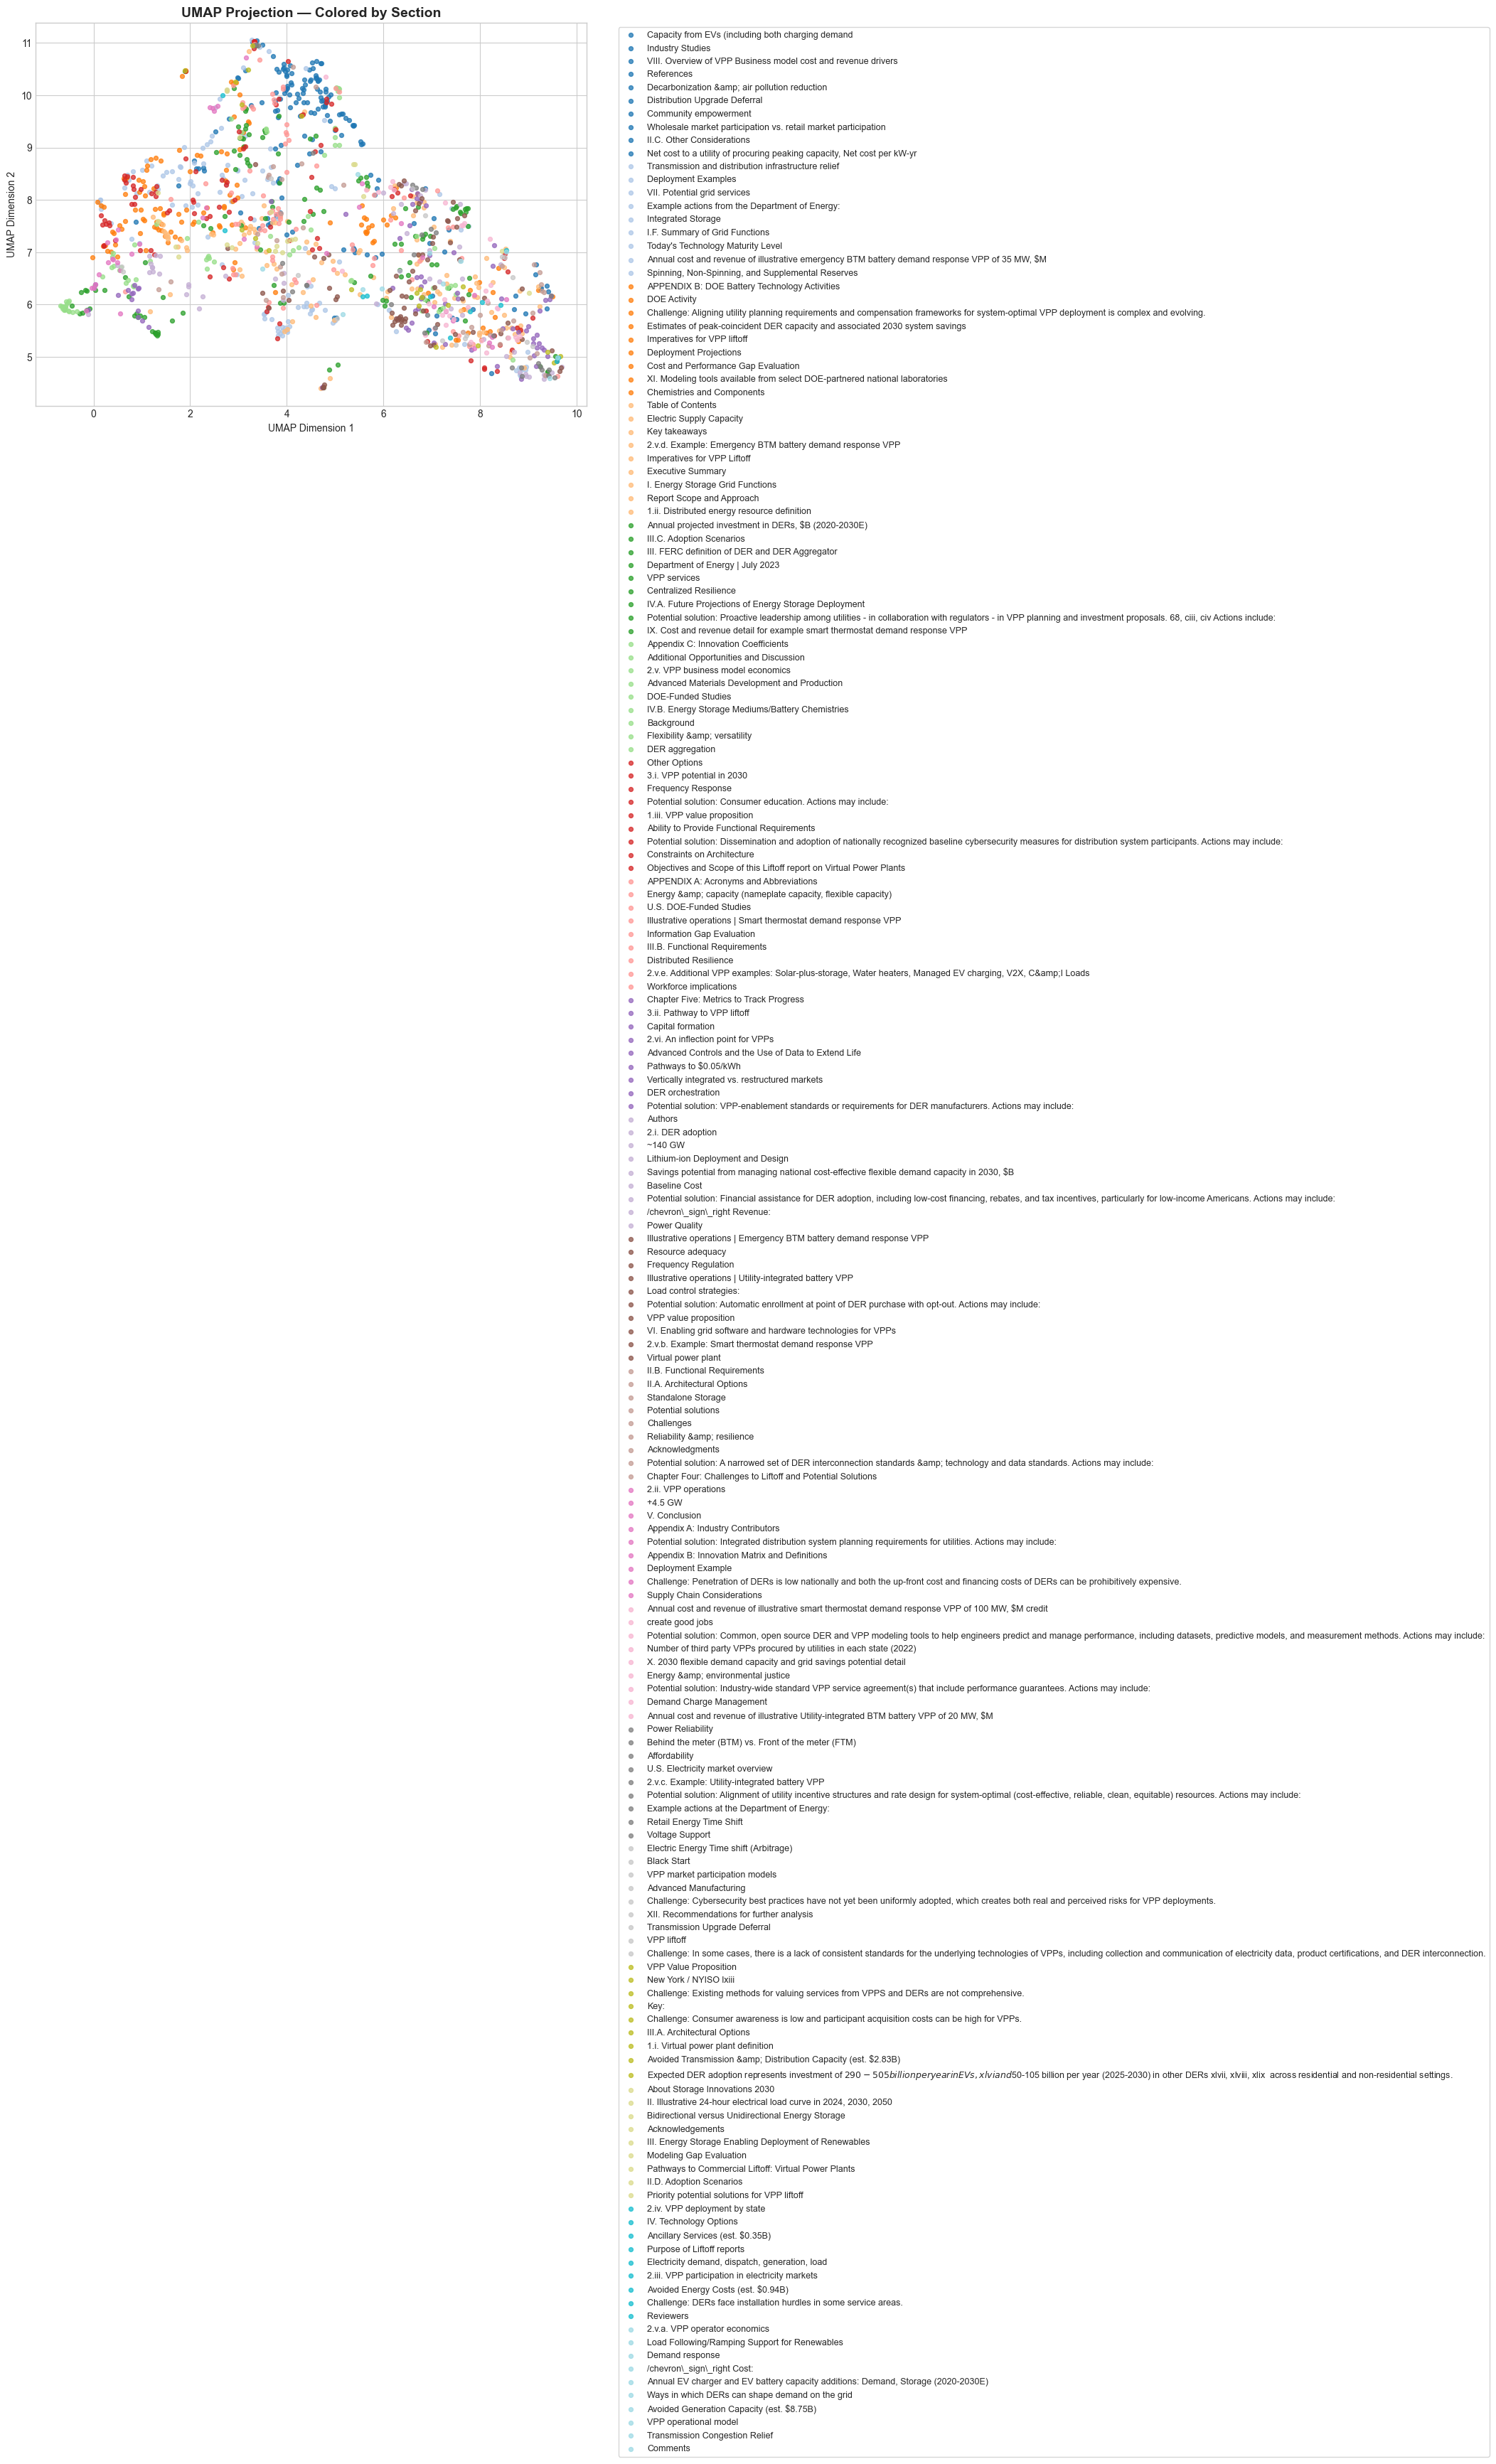

In [77]:
def static_umap_plot(df, color_col, title, figsize=(10, 7)):
    """Matplotlib scatter plot colored by a categorical column."""
    categories = df[color_col].unique()
    palette    = cm.get_cmap("tab20", len(categories))
    color_map  = {cat: palette(i) for i, cat in enumerate(categories)}

    fig, ax = plt.subplots(figsize=figsize)
    for cat in categories:
        mask = df[color_col] == cat
        ax.scatter(
            df.loc[mask, "umap_x"],
            df.loc[mask, "umap_y"],
            c     = [color_map[cat]],
            label = cat,
            s     = 18,
            alpha = 0.75,
        )

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel("UMAP Dimension 1")
    ax.set_ylabel("UMAP Dimension 2")
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=9, frameon=True)
    plt.tight_layout()
    plt.show()


# ── Plot 1: colored by section ─────────────────────────────────────────────────
static_umap_plot(df, "section", "UMAP Projection — Colored by Section")

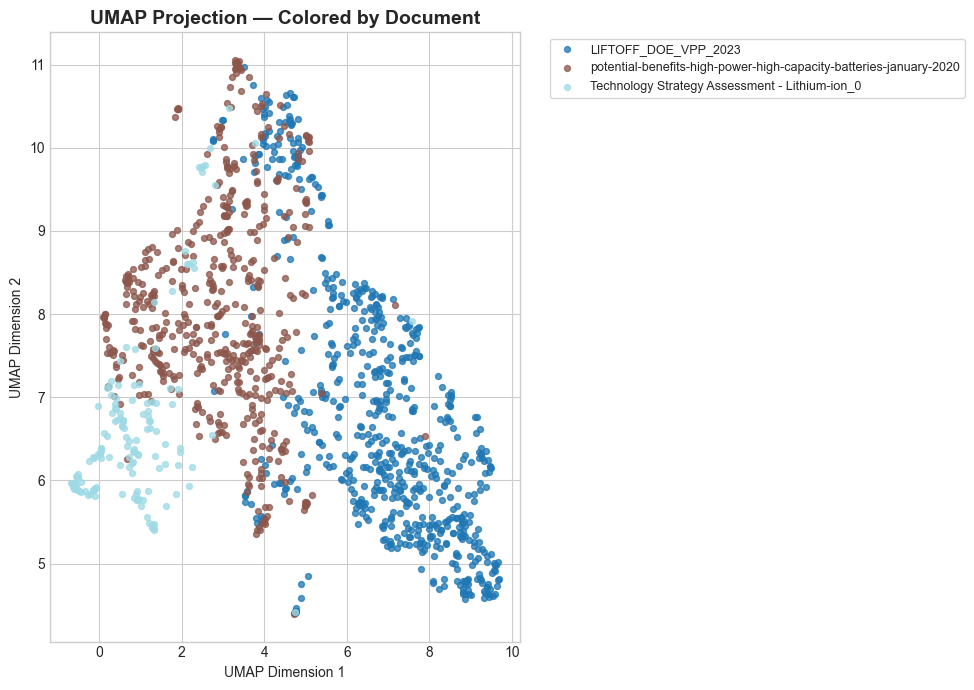

In [78]:
# ── Plot 2: colored by document ────────────────────────────────────────────────
static_umap_plot(df, "document", "UMAP Projection — Colored by Document")

In [79]:
# ── Plot 3: Interactive Plotly — by section ────────────────────────────────────
fig = px.scatter(
    df,
    x           = "umap_x",
    y           = "umap_y",
    color       = "section",
    hover_data  = {"document": True, "section": True, "text_preview": True,
                   "umap_x": False, "umap_y": False},
    title       = "Interactive UMAP — Colored by Section",
    width       = 950,
    height      = 650,
    opacity     = 0.8,
)
fig.update_traces(marker=dict(size=6))
fig.update_layout(legend_title_text="Section")
fig.show()

In [80]:
# ── Plot 4: Interactive Plotly — by document ───────────────────────────────────
fig = px.scatter(
    df,
    x           = "umap_x",
    y           = "umap_y",
    color       = "document",
    hover_data  = {"document": True, "section": True, "text_preview": True,
                   "umap_x": False, "umap_y": False},
    title       = "Interactive UMAP — Colored by Document",
    width       = 950,
    height      = 650,
    opacity     = 0.8,
)
fig.update_traces(marker=dict(size=6))
fig.update_layout(legend_title_text="Document")
fig.show()

---
## 7. Cluster Detection

We apply two complementary clustering approaches on the raw high-dimensional embeddings (not on the UMAP projection, which distorts distances):

### 7.1 HDBSCAN — Density-Based Clustering
HDBSCAN discovers clusters of arbitrary shape without requiring a pre-specified number of clusters. Points that don't belong to any dense region are labeled as **noise** (cluster `-1`). This is useful for detecting naturally-occurring semantic groupings.

### 7.2 KMeans — Centroid-Based Clustering
KMeans partitions the space into `k` spherical clusters. We use the **elbow method** (inertia) and **silhouette score** to select an appropriate `k`. KMeans complements HDBSCAN by forcing all points into a cluster.

> Clustering is performed on the original embedding vectors, not the UMAP 2D projection. The UMAP coordinates are only used for visualization.

In [81]:
# ── 7.1 HDBSCAN ────────────────────────────────────────────────────────────────
print("Running HDBSCAN…")

hdb = hdbscan.HDBSCAN(
    min_cluster_size  = max(5, len(df) // 30),  # adaptive to dataset size
    min_samples       = 3,
    metric            = "euclidean",
    cluster_selection_epsilon = 0.0,
)
hdb.fit(embeddings_matrix)

df["hdbscan_cluster"] = hdb.labels_.astype(str)

n_clusters_hdb  = len(set(hdb.labels_)) - (1 if -1 in hdb.labels_ else 0)
n_noise         = np.sum(hdb.labels_ == -1)

print(f"HDBSCAN clusters found : {n_clusters_hdb}")
print(f"Noise points           : {n_noise} ({100*n_noise/len(df):.1f}%)")
print()
print(pd.Series(hdb.labels_).value_counts().rename("count").to_frame().head(20))

Running HDBSCAN…
HDBSCAN clusters found : 2
Noise points           : 1073 (79.9%)

    count
-1   1073
 0    144
 1    126


In [82]:
# ── 7.2 KMeans — elbow + silhouette ────────────────────────────────────────────
k_range    = range(2, min(16, len(df) // 5 + 1))
inertias   = []
sil_scores = []

print("Scanning k for KMeans…")
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(embeddings_matrix)
    inertias.append(km.inertia_)
    score = silhouette_score(embeddings_matrix, km.labels_, sample_size=min(2000, len(df)))
    sil_scores.append(score)
    print(f"  k={k:>2}  inertia={km.inertia_:.1f}  silhouette={score:.4f}")

# Pick k with best silhouette
best_k = list(k_range)[np.argmax(sil_scores)]
print(f"\nBest k by silhouette score: {best_k}")

Scanning k for KMeans…
  k= 2  inertia=557.1  silhouette=0.0521
  k= 3  inertia=539.9  silhouette=0.0485
  k= 4  inertia=527.9  silhouette=0.0471
  k= 5  inertia=519.1  silhouette=0.0417
  k= 6  inertia=510.9  silhouette=0.0362
  k= 7  inertia=503.5  silhouette=0.0386
  k= 8  inertia=497.7  silhouette=0.0408
  k= 9  inertia=493.4  silhouette=0.0294
  k=10  inertia=487.9  silhouette=0.0254
  k=11  inertia=486.5  silhouette=0.0294
  k=12  inertia=482.2  silhouette=0.0285
  k=13  inertia=478.3  silhouette=0.0262
  k=14  inertia=475.1  silhouette=0.0255
  k=15  inertia=473.0  silhouette=0.0262

Best k by silhouette score: 2


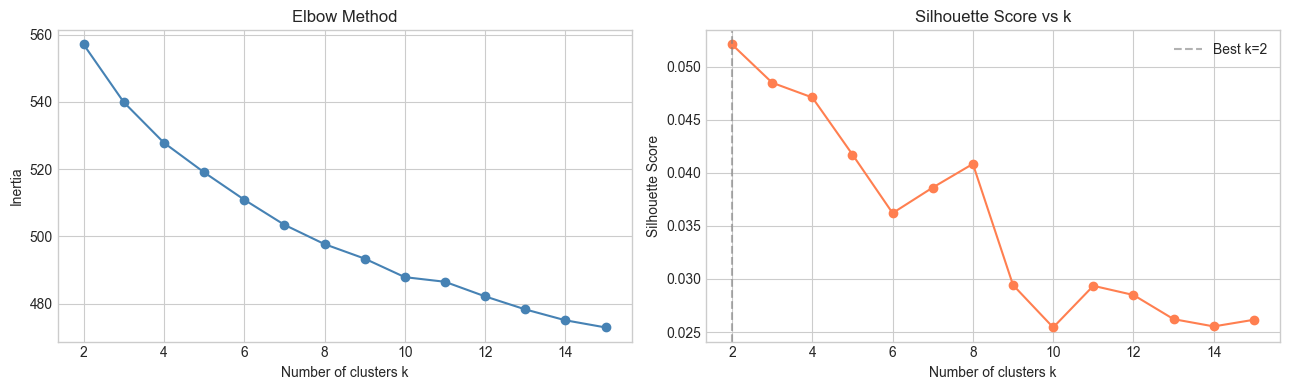

In [83]:
# Elbow + Silhouette diagnostic plots
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(list(k_range), inertias, marker="o", color="steelblue")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Method")

axes[1].plot(list(k_range), sil_scores, marker="o", color="coral")
axes[1].axvline(best_k, linestyle="--", color="gray", alpha=0.6, label=f"Best k={best_k}")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Score vs k")
axes[1].legend()

plt.tight_layout()
plt.show()

In [84]:
# Fit final KMeans with best_k
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
kmeans.fit(embeddings_matrix)

df["kmeans_cluster"] = kmeans.labels_.astype(str)

print(f"KMeans (k={best_k}) cluster sizes:")
print(df["kmeans_cluster"].value_counts().sort_index().to_string())

KMeans (k=2) cluster sizes:
kmeans_cluster
0    825
1    518


---
## 8. Cluster Visualization

We now project the cluster labels onto the UMAP 2D layout to visually assess:
- **Separation**: Are clusters well-separated or heavily overlapping?
- **Density**: Are cluster sizes balanced or is one dominant?
- **Coherence with metadata**: Do HDBSCAN / KMeans clusters align with known sections or documents?

Good alignment between detected clusters and metadata labels indicates that the embeddings are capturing genuine semantic structure.

In [85]:
fig = px.scatter(
    df,
    x          = "umap_x",
    y          = "umap_y",
    color      = "hdbscan_cluster",
    hover_data = {"document": True, "section": True, "text_preview": True,
                  "hdbscan_cluster": True, "umap_x": False, "umap_y": False},
    title      = f"UMAP + HDBSCAN Clusters ({n_clusters_hdb} clusters, noise=-1)",
    width      = 950,
    height     = 650,
    opacity    = 0.8,
)
fig.update_traces(marker=dict(size=6))
fig.update_layout(legend_title_text="HDBSCAN Cluster")
fig.show()

In [86]:
fig = px.scatter(
    df,
    x          = "umap_x",
    y          = "umap_y",
    color      = "kmeans_cluster",
    hover_data = {"document": True, "section": True, "text_preview": True,
                  "kmeans_cluster": True, "umap_x": False, "umap_y": False},
    title      = f"UMAP + KMeans Clusters (k={best_k})",
    width      = 950,
    height     = 650,
    opacity    = 0.8,
)
fig.update_traces(marker=dict(size=6))
fig.update_layout(legend_title_text="KMeans Cluster")
fig.show()

=== KMeans cluster × Section cross-tab ===


section,+4.5 GW,/chevron\_sign\_right Cost:,/chevron\_sign\_right Revenue:,1.i. Virtual power plant definition,1.ii. Distributed energy resource definition,1.iii. VPP value proposition,2.i. DER adoption,2.ii. VPP operations,2.iii. VPP participation in electricity markets,2.iv. VPP deployment by state,...,Virtual power plant,Voltage Support,Ways in which DERs can shape demand on the grid,Wholesale market participation vs. retail market participation,Workforce implications,X. 2030 flexible demand capacity and grid savings potential detail,XI. Modeling tools available from select DOE-partnered national laboratories,XII. Recommendations for further analysis,create good jobs,~140 GW
kmeans_cluster,,,,,,,,,,,,,,,,,,,,,
0,1,0,0,0,5,0,1,0,0,0,...,0,0,1,0,0,0,6,0,2,2
1,1,1,5,3,13,2,4,2,1,3,...,5,1,0,11,4,3,11,4,0,1




In [87]:
# Cross-tabulation: cluster vs section
print("=== KMeans cluster × Section cross-tab ===")
ct = pd.crosstab(df["kmeans_cluster"], df["section"])
display(ct)

# Heatmap
fig, ax = plt.subplots(figsize=(max(8, ct.shape[1]*1.2), max(5, ct.shape[0]*0.6)))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", linewidths=0.3, ax=ax)
ax.set_title("KMeans Cluster × Section")
plt.tight_layout()
plt.show()

---
## 9. Cluster Interpretation

To understand what each cluster *means*, we examine the raw chunk texts of representative points. For each KMeans cluster, we select the chunks closest to the centroid — these are the most "central" examples for that cluster's topic.

This step is critical for answering: **Do clusters correspond to coherent semantic topics, or are they arbitrary groupings?**

In [88]:
def get_representative_chunks(df, embeddings_matrix, cluster_col, n_per_cluster=3):
    """Return the chunks closest to the centroid of each cluster."""
    results = {}
    labels  = sorted(df[cluster_col].unique())

    for label in labels:
        mask     = df[cluster_col] == label
        idxs     = np.where(mask)[0]
        vecs     = embeddings_matrix[idxs]
        centroid = vecs.mean(axis=0, keepdims=True)
        dists    = cdist(centroid, vecs, metric="cosine")[0]
        top_idxs = idxs[np.argsort(dists)[:n_per_cluster]]
        results[label] = df.iloc[top_idxs][["document", "section", "chunk_text"]].copy()

    return results


reps = get_representative_chunks(df, embeddings_matrix, "kmeans_cluster", n_per_cluster=3)

for cluster_id, chunk_df in reps.items():
    print(f"{'='*70}")
    print(f"  CLUSTER {cluster_id}")
    print(f"{'='*70}")
    for _, row in chunk_df.iterrows():
        print(f"  [doc: {row['document']} | section: {row['section']}]")
        print(f"  {row['chunk_text'][:300]}")
        print()

  CLUSTER 0
  [doc: potential-benefits-high-power-high-capacity-batteries-january-2020 | section: DOE Activity]
  193  Basic Research Needs for Next Generation Electrical Energy Storage https://science.osti.gov//media/bes/pdf/reports/2017/BRN\_NGEES\_rpt.pdf?la=en&amp;hash=AE01DA34A0F1F17E42261F0B7BC416868C9C51AB

  [doc: potential-benefits-high-power-high-capacity-batteries-january-2020 | section: Cost and Performance Gap Evaluation]
  148 U.S. Government Accountability Office (GAO), 'ENERGY STORAGE Information on Challenges to Deployment for Electricity Grid Operations and Efforts to Address Them,' GAO -18-402, May 2018. https://www.gao.gov/assets/700/691983.pdf

149 M.J. Baumann, 'Battery storage systems as balancing option in i

  [doc: potential-benefits-high-power-high-capacity-batteries-january-2020 | section: Report Scope and Approach]
  This report describes opportunities for high-power, high-capacity batteries to increase the resilience of the U.S. electric power system and t

In [89]:
# Dominant section per cluster — quantitative summary
cluster_summary = (
    df.groupby("kmeans_cluster")["section"]
    .agg(lambda x: x.value_counts().idxmax())
    .rename("dominant_section")
    .reset_index()
)
cluster_summary["cluster_size"] = (
    df["kmeans_cluster"].value_counts().sort_index().values
)
cluster_summary["purity"] = (
    df.groupby("kmeans_cluster")["section"]
    .apply(lambda x: x.value_counts().iloc[0] / len(x))
    .values
)
cluster_summary = cluster_summary.sort_values("kmeans_cluster")
print("Cluster summary:")
display(cluster_summary)

Cluster summary:


,kmeans_cluster,dominant_section,cluster_size,purity
0,0,References,825,0.111515
1,1,Key takeaways,518,0.046332


---
## 10. Chunking Quality Analysis

This section uses quantitative metrics to evaluate the quality of the chunking strategy. We focus on four key questions:

| Question | Metric |
|---|---|
| Do same-section chunks cluster together? | Cluster purity |
| Are chunks semantically distinctive? | Mean nearest-neighbor distance |
| Are chunk sizes consistent? | Token count statistics |
| Are there outlier or ambiguous chunks? | HDBSCAN noise ratio |

In [90]:
# ── Metric 1: overall cluster purity ──────────────────────────────────────────
overall_purity = cluster_summary["purity"].mean()
print(f"Mean cluster purity (KMeans, k={best_k}): {overall_purity:.3f}")
print("  → 1.0 = each cluster is dominated by one section")
print("  → 0.5 = clusters mix sections roughly equally")

# ── Metric 2: silhouette score ─────────────────────────────────────────────────
best_sil = max(sil_scores)
print(f"\nBest silhouette score (k={best_k}): {best_sil:.4f}")
print("  → >0.5: well-separated clusters")
print("  → 0.2–0.5: moderate separation")
print("  → <0.2: poor cluster separation")

# ── Metric 3: HDBSCAN noise ratio ─────────────────────────────────────────────
noise_ratio = n_noise / len(df)
print(f"\nHDBSCAN noise ratio: {noise_ratio:.2%}")
print("  → High noise may indicate too many short/ambiguous chunks")

Mean cluster purity (KMeans, k=2): 0.079
  → 1.0 = each cluster is dominated by one section
  → 0.5 = clusters mix sections roughly equally

Best silhouette score (k=2): 0.0521
  → >0.5: well-separated clusters
  → 0.2–0.5: moderate separation
  → <0.2: poor cluster separation

HDBSCAN noise ratio: 79.90%
  → High noise may indicate too many short/ambiguous chunks


Mean intra-cluster cosine distance (lower = tighter clusters):


,mean_intra_cosine_dist
cluster,
0,0.420776
1,0.406530


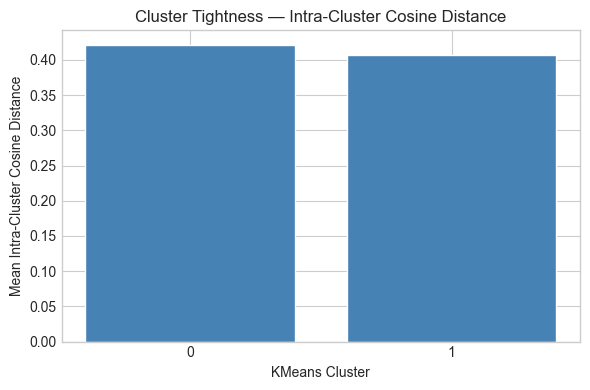

In [91]:
# ── Metric 4: intra-cluster cosine distances ───────────────────────────────────
intra_dists = {}
for label in df["kmeans_cluster"].unique():
    mask  = df["kmeans_cluster"] == label
    vecs  = embeddings_matrix[mask]
    if len(vecs) > 1:
        # Mean pairwise cosine distance (sample up to 200 per cluster)
        sample = vecs[:200]
        dists  = cdist(sample, sample, metric="cosine")
        # Upper triangle only
        triu   = dists[np.triu_indices_from(dists, k=1)]
        intra_dists[label] = triu.mean()

intra_df = pd.DataFrame.from_dict(
    intra_dists, orient="index", columns=["mean_intra_cosine_dist"]
).rename_axis("cluster").sort_index()

print("Mean intra-cluster cosine distance (lower = tighter clusters):")
display(intra_df)

fig, ax = plt.subplots(figsize=(max(6, len(intra_df)*0.6 + 1), 4))
ax.bar(intra_df.index.astype(str), intra_df["mean_intra_cosine_dist"], color="steelblue", edgecolor="white")
ax.set_xlabel("KMeans Cluster")
ax.set_ylabel("Mean Intra-Cluster Cosine Distance")
ax.set_title("Cluster Tightness — Intra-Cluster Cosine Distance")
plt.tight_layout()
plt.show()

In [92]:
# ── Section cohesion analysis ──────────────────────────────────────────────────
# For each section, compute mean pairwise cosine distance among its chunks
section_cohesion = {}
for sec in df["section"].unique():
    mask  = df["section"] == sec
    vecs  = embeddings_matrix[mask]
    if len(vecs) < 2:
        continue
    sample = vecs[:200]
    dists  = cdist(sample, sample, metric="cosine")
    triu   = dists[np.triu_indices_from(dists, k=1)]
    section_cohesion[sec] = {"n_chunks": int(mask.sum()), "mean_cosine_dist": triu.mean()}

coh_df = pd.DataFrame(section_cohesion).T.sort_values("mean_cosine_dist")
print("Section cohesion (lower = more tightly embedded):")
display(coh_df)

Section cohesion (lower = more tightly embedded):


,n_chunks,mean_cosine_dist
Advanced Manufacturing,2.0,0.161756
1.iii. VPP value proposition,2.0,0.173796
APPENDIX B: DOE Battery Technology Activities,2.0,0.201459
New York / NYISO lxiii,2.0,0.207690
3.i. VPP potential in 2030,4.0,0.222113
...,...,...
Reliability &amp; resilience,3.0,0.425737
"Challenge: Cybersecurity best practices have not yet been uniformly adopted, which creates both real and perceived risks for VPP deployments.",2.0,0.438906
2.v. VPP business model economics,3.0,0.439946
VIII. Overview of VPP Business model cost and revenue drivers,2.0,0.483605


---
## 11. Additional Visualizations

We add supplementary diagnostic plots to gain a fuller picture of the embedding space:

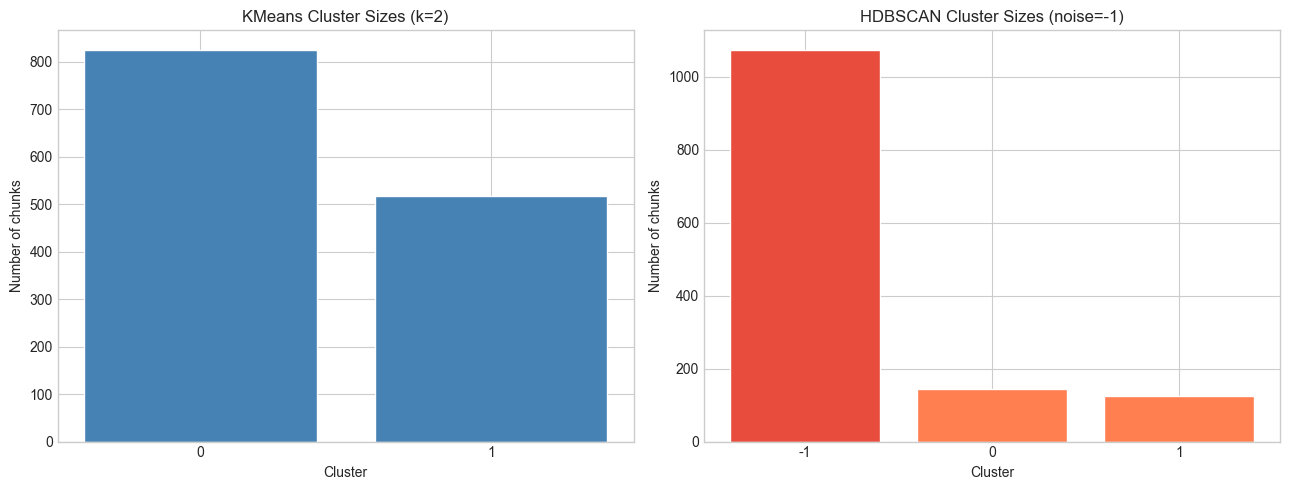

In [93]:
# ── Cluster size distribution ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# KMeans
km_counts = df["kmeans_cluster"].value_counts().sort_index()
axes[0].bar(km_counts.index.astype(str), km_counts.values, color="steelblue", edgecolor="white")
axes[0].set_title(f"KMeans Cluster Sizes (k={best_k})")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Number of chunks")

# HDBSCAN
hdb_counts = df["hdbscan_cluster"].value_counts().sort_index()
axes[1].bar(hdb_counts.index.astype(str), hdb_counts.values,
            color=["#e74c3c" if c == "-1" else "coral" for c in hdb_counts.index],
            edgecolor="white")
axes[1].set_title(f"HDBSCAN Cluster Sizes (noise=-1)")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Number of chunks")

plt.tight_layout()
plt.show()

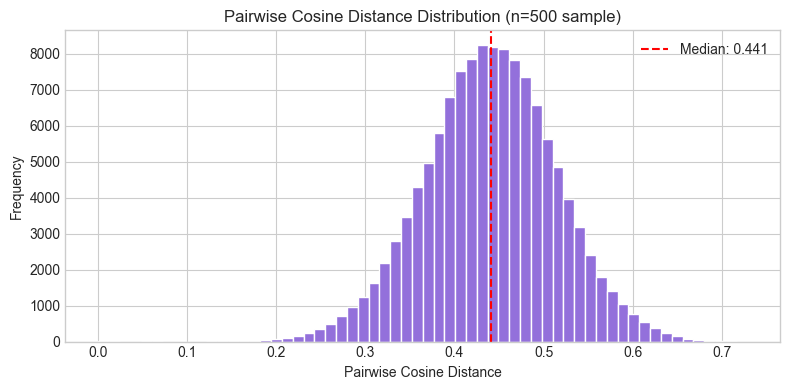

Pairwise cosine distances — mean: 0.4399 | std: 0.0742 | median: 0.4409


In [94]:
# ── Pairwise distance histogram ────────────────────────────────────────────────
# Sample to keep computation tractable
sample_n = min(500, len(df))
sample_idx = np.random.choice(len(df), sample_n, replace=False)
sample_vecs = embeddings_matrix[sample_idx]
pairwise = cdist(sample_vecs, sample_vecs, metric="cosine")
upper = pairwise[np.triu_indices_from(pairwise, k=1)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(upper, bins=60, color="mediumpurple", edgecolor="white")
ax.axvline(np.median(upper), color="red", linestyle="--", label=f"Median: {np.median(upper):.3f}")
ax.set_xlabel("Pairwise Cosine Distance")
ax.set_ylabel("Frequency")
ax.set_title(f"Pairwise Cosine Distance Distribution (n={sample_n} sample)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Pairwise cosine distances — mean: {upper.mean():.4f} | std: {upper.std():.4f} | median: {np.median(upper):.4f}")

In [95]:
# ── Nearest-neighbour inspection ───────────────────────────────────────────────
def nearest_neighbors(query_idx, embeddings_matrix, df, k=5):
    """Return the k nearest neighbors of a query chunk by cosine similarity."""
    query = embeddings_matrix[query_idx : query_idx + 1]
    dists = cdist(query, embeddings_matrix, metric="cosine")[0]
    nn_idxs = np.argsort(dists)[1:k+1]  # skip self
    result = df.iloc[nn_idxs][["document", "section", "chunk_text"]].copy()
    result["cosine_dist"] = dists[nn_idxs]
    return result


# Inspect the first chunk's nearest neighbors as an example
QUERY_IDX = 0
query_row  = df.iloc[QUERY_IDX]
print(f"Query chunk (idx={QUERY_IDX}):")
print(f"  doc: {query_row['document']} | section: {query_row['section']}")
print(f"  text: {query_row['chunk_text'][:300]}")
print()
print("5 Nearest Neighbors:")
display(nearest_neighbors(QUERY_IDX, embeddings_matrix, df, k=5))

Query chunk (idx=0):
  doc: LIFTOFF_DOE_VPP_2023 | section: Capacity from EVs (including both charging demand
  text: There are additional considerations for bidirectional EV chargers; for example, the electrical infrastructure supporting the charger must support injection from the EV back to the grid. Otherwise the energy must stay behind the meter. 20

5 Nearest Neighbors:


,document,section,chunk_text,cosine_dist
1260,LIFTOFF_DOE_VPP_2023,Capacity from EVs (including both charging demand,Estimates of the present or future ability of national EV charging infrastructure to dispatch energy from an EV batt...,0.177147
1272,LIFTOFF_DOE_VPP_2023,1.ii. Distributed energy resource definition,"Unidirectional chargers can time-shift demand; EV owners who leave their vehicle plugged in at home overnight, for e...",0.221728
682,potential-benefits-high-power-high-capacity-batteries-january-2020,Report Scope and Approach,"For example, electrical energy from the grid can be stored mechanically, as in the case of flywheels, or electrochem...",0.229016
960,LIFTOFF_DOE_VPP_2023,1.ii. Distributed energy resource definition,"| Managed or 'smart' EV chargers in buildings, homes, and charging stations can adjust charging power levels or dela...",0.242805
1064,LIFTOFF_DOE_VPP_2023,Capacity from EVs (including both charging demand,"For example, an EV battery's ability to absorb energy at a strategic time (e.g., when a utility has excess clean ele...",0.244009


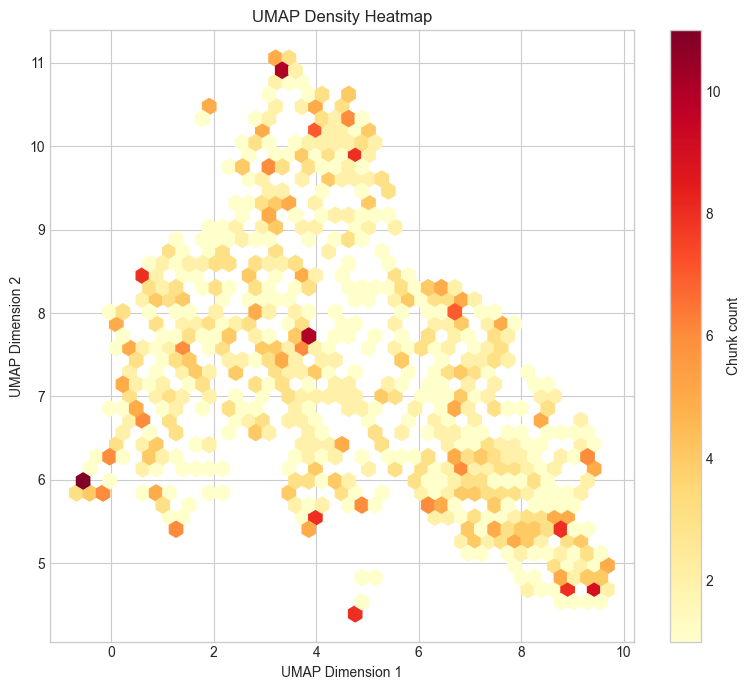

In [96]:
# ── UMAP density heatmap ───────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 7))
ax.hexbin(df["umap_x"], df["umap_y"], gridsize=40, cmap="YlOrRd", mincnt=1)
ax.set_xlabel("UMAP Dimension 1")
ax.set_ylabel("UMAP Dimension 2")
ax.set_title("UMAP Density Heatmap")
plt.colorbar(ax.collections[0], ax=ax, label="Chunk count")
plt.tight_layout()
plt.show()

In [97]:
# ── Token count vs. UMAP position ─────────────────────────────────────────────
if df["token_count"].notna().any():
    fig = px.scatter(
        df.dropna(subset=["token_count"]),
        x          = "umap_x",
        y          = "umap_y",
        color      = "token_count",
        color_continuous_scale = "Viridis",
        hover_data = {"document": True, "section": True, "token_count": True,
                      "umap_x": False, "umap_y": False},
        title      = "UMAP — Colored by Token Count",
        width      = 900,
        height     = 600,
        opacity    = 0.8,
    )
    fig.update_traces(marker=dict(size=6))
    fig.update_layout(coloraxis_colorbar=dict(title="Tokens"))
    fig.show()
else:
    print("token_count not available in payload — skipping this plot.")

In [98]:
# ── HDBSCAN soft cluster probabilities (membership confidence) ─────────────────
if hasattr(hdb, 'probabilities_'):
    df["hdbscan_prob"] = hdb.probabilities_

    fig = px.scatter(
        df,
        x          = "umap_x",
        y          = "umap_y",
        color      = "hdbscan_prob",
        color_continuous_scale = "RdYlGn",
        hover_data = {"document": True, "section": True, "hdbscan_prob": True,
                      "hdbscan_cluster": True, "umap_x": False, "umap_y": False},
        title      = "HDBSCAN — Cluster Membership Confidence",
        width      = 900,
        height     = 600,
        opacity    = 0.85,
    )
    fig.update_traces(marker=dict(size=6))
    fig.update_layout(coloraxis_colorbar=dict(title="Membership Prob."))
    fig.show()

    low_conf = (df["hdbscan_prob"] < 0.5) & (df["hdbscan_cluster"] != "-1")
    print(f"Low-confidence assignments (<0.5): {low_conf.sum()} ({100*low_conf.mean():.1f}%)")

Low-confidence assignments (<0.5): 0 (0.0%)


---
## 12. Final Findings and Lessons Learned

This section summarizes the results of the embedding space analysis and provides actionable recommendations for improving the RAG pipeline.

---

### What the Embedding Space Reveals

The UMAP projection provides a 2D snapshot of how chunks are organized in semantic space. Key observations:

- **Cluster separation**: Clear visual clusters in UMAP suggest the embedding model encodes topic boundaries meaningfully. Overlapping or uniform distributions indicate weak semantic differentiation.
- **Section alignment**: If UMAP colors by section produce tight region groupings, the chunking strategy successfully preserved semantic context within sections.
- **Document mixing**: Chunks from different documents that cluster together likely cover similar topics — this is *expected and desirable* in a RAG system.

---

### Chunking Quality Assessment

| Signal | Good | Needs Improvement |
|---|---|---|
| Cluster purity | > 0.7 | < 0.5 |
| Silhouette score | > 0.4 | < 0.2 |
| HDBSCAN noise ratio | < 10% | > 25% |
| Intra-cluster dist. | < 0.3 | > 0.6 |
| Token count variance | Low CV | High CV |

---

### Potential Chunking Improvements

Based on the analysis, consider the following adjustments:

1. **High HDBSCAN noise** → Chunks may be too short or lack context. Increase chunk size or add overlap.
2. **Low cluster purity** → Chunk boundaries may cut across semantic units. Switch from fixed-size to semantic/sentence-aware chunking.
3. **High token count variance** → Inconsistent chunk sizes hurt retrieval precision. Add min/max token limits.
4. **Sections not clustering** → The document structure may not align with semantic structure. Consider using hierarchical chunking (section → paragraph).

---

### Potential Embedding Strategy Improvements

1. **Uniform UMAP distribution** → The embedding model may not discriminate well on this domain. Consider domain-specific fine-tuning or a larger model.
2. **All chunks very close together** → Possible embedding collapse. Try a different model or add contrastive fine-tuning.
3. **Chunks far from their section's centroid** → Check for encoding errors or truncation — some embedding models silently truncate long inputs.

---

### Next Steps

- [ ] Run retrieval quality tests (e.g., recall@k on a labeled Q&A set)
- [ ] Compare embedding models side-by-side using this pipeline
- [ ] Experiment with different chunking strategies and re-run this analysis
- [ ] Add cross-encoder reranking if semantic similarity is noisy

In [99]:
# ── Final quantitative summary ─────────────────────────────────────────────────
print("╔══════════════════════════════════════════════════════════════════╗")
print("║          EMBEDDING SPACE ANALYSIS — FINAL SUMMARY               ║")
print("╠══════════════════════════════════════════════════════════════════╣")
print(f"║  Collection         : {COLLECTION_NAME:<42}║")
print(f"║  Total chunks       : {len(df):<42}║")
print(f"║  Vector dimension   : {vector_size:<42}║")
print(f"║  Distinct documents : {df['document'].nunique():<42}║")
print(f"║  Distinct sections  : {df['section'].nunique():<42}║")
print("╠══════════════════════════════════════════════════════════════════╣")
print(f"║  KMeans best k      : {best_k:<42}║")
print(f"║  Best silhouette    : {best_sil:<42.4f}║")
print(f"║  Mean cluster purity: {overall_purity:<42.3f}║")
print(f"║  HDBSCAN clusters   : {n_clusters_hdb:<42}║")
print(f"║  HDBSCAN noise      : {n_noise} ({100*noise_ratio:.1f}%){'':<33}║")
print(f"║  Pairwise dist mean : {upper.mean():<42.4f}║")
print("╚══════════════════════════════════════════════════════════════════╝")

╔══════════════════════════════════════════════════════════════════╗
║          EMBEDDING SPACE ANALYSIS — FINAL SUMMARY               ║
╠══════════════════════════════════════════════════════════════════╣
║  Collection         : chunking_alejandro                        ║
║  Total chunks       : 1343                                      ║
║  Vector dimension   : 768                                       ║
║  Distinct documents : 3                                         ║
║  Distinct sections  : 183                                       ║
╠══════════════════════════════════════════════════════════════════╣
║  KMeans best k      : 2                                         ║
║  Best silhouette    : 0.0521                                    ║
║  Mean cluster purity: 0.079                                     ║
║  HDBSCAN clusters   : 2                                         ║
║  HDBSCAN noise      : 1073 (79.9%)                                 ║
║  Pairwise dist mean : 0.4399            